In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn lightgbm xgboost catboost imbalanced-learn lazypredict

In [2]:
import pandas as pd

df = pd.read_csv("train.csv")

In [3]:
features = [
    'cvv_retry_count',
    'velocity_score',
    'merchant_risk_score',
    'txn_count_last_24h'
]

# Tính trung bình từng đặc trưng theo nhãn
result = df.groupby('is_fraud')[features].mean()

# Chuyển hàng thành cột
result = result.T

# Đổi tên cột
result = result.rename(columns={
    0: 'Không gian lận (trung bình)',
    1: 'Gian lận (trung bình)'
})

# Hiển thị 3 chữ số thập phân
display(result.round(3))

is_fraud,Không gian lận (trung bình),Gian lận (trung bình)
cvv_retry_count,0.077,0.557
velocity_score,18.786,27.404
merchant_risk_score,35.011,47.368
txn_count_last_24h,2.973,3.652


In [4]:
print(df.dtypes)

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [5]:
import pandas as pd

null_stats = pd.DataFrame({
    'Số giá trị Null': df.isnull().sum(),
    'Tỷ lệ Null (%)': df.isnull().mean() * 100
})

# Sắp xếp theo tỷ lệ Null giảm dần
null_stats = null_stats.sort_values(
    by='Tỷ lệ Null (%)',
    ascending=False
)

display(null_stats.round(2))

,Số giá trị Null,Tỷ lệ Null (%)
id,0,0.0
amount_usd,0,0.0
hours_since_last_txn,0,0.0
txn_count_last_24h,0,0.0
distance_from_home_km,0,0.0
card_age_months,0,0.0
customer_age,0,0.0
account_balance_usd,0,0.0
cvv_retry_count,0,0.0
velocity_score,0,0.0


In [6]:
import pandas as pd

label_distribution = pd.DataFrame({
    'Số lượng': df['is_fraud'].value_counts(),
    'Tỷ lệ (%)': df['is_fraud'].value_counts(normalize=True) * 100
})

display(label_distribution.round(2))

,Số lượng,Tỷ lệ (%)
is_fraud,,
0.0,688271,98.33
1.0,11689,1.67


In [9]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


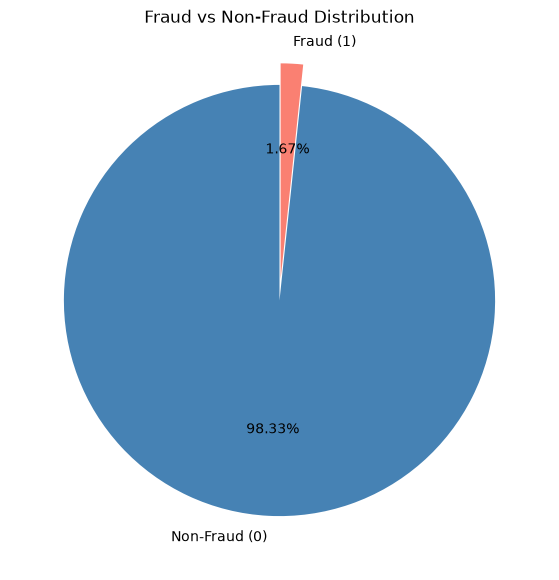

In [7]:
import matplotlib.pyplot as plt
counts = df['is_fraud'].value_counts().sort_index()

plt.figure(figsize=(7, 7))

plt.pie(
    counts,
    labels=['Non-Fraud (0)', 'Fraud (1)'],
    autopct='%1.2f%%',
    startangle=90,
    colors=['steelblue', 'salmon'],
    explode=[0, 0.1]
)

plt.title('Fraud vs Non-Fraud Distribution')
plt.show()

In [8]:
cat_cols = df.select_dtypes(
    include=['object', 'string', 'category']
).columns

for col in cat_cols:
    print(f"\nColumn: {col}")
    print("Unique values:", df[col].nunique())
    print("Values:", df[col].unique())


Column: merchant_category
Unique values: 12
Values: <StringArray>
[      'Groceries',   'Online Retail',       'Utilities',     'Electronics',
      'Healthcare',     'Restaurants',            'Fuel',       'Streaming',
 'Crypto Exchange',          'Gaming',          'Travel',      'Gift Cards']
Length: 12, dtype: str

Column: card_type
Unique values: 5
Values: <StringArray>
['Mastercard', 'Visa', 'Amex', 'RuPay', 'Discover']
Length: 5, dtype: str

Column: auth_method
Unique values: 5
Values: <StringArray>
['OTP', 'PIN', '3D Secure', 'Biometric', 'No Authentication']
Length: 5, dtype: str

Column: channel
Unique values: 5
Values: <StringArray>
['POS', 'In-App', 'Online', 'ATM', 'Contactless']
Length: 5, dtype: str

Column: device_type
Unique values: 8
Values: <StringArray>
[       'iPhone', 'Android Phone',        'Tablet',    'Windows PC',
  'POS Terminal',           'Mac',   'ATM Machine',   'Smart Watch']
Length: 8, dtype: str


In [9]:
cat_cols = [
    'merchant_category',
    'card_type',
    'auth_method',
    'channel',
    'device_type'
]

df = pd.get_dummies(
    df,
    columns=cat_cols,
    dtype=int
)
print("Số cột sau Encoding:", df.shape[1])

Số cột sau Encoding: 56


In [10]:
# Lấy danh sách các cột kiểu bool
bool_cols = df.select_dtypes(include=['bool']).columns

# Chuyển bool thành int (0 và 1)
df[bool_cols] = df[bool_cols].astype(int)

# Kiểm tra kết quả
print(df[bool_cols].head())

   is_foreign_transaction  is_new_merchant  used_vpn  ip_country_mismatch  \
0                       0                0         0                    0   
1                       0                0         0                    0   
2                       0                0         1                    0   
3                       0                0         0                    0   
4                       0                0         0                    0   

   billing_shipping_mismatch  is_ai_generated_scam_attempt  
0                          0                             0  
1                          0                             0  
2                          0                             0  
3                          0                             0  
4                          0                             0  


In [11]:
import pandas as pd

numeric_df = df.select_dtypes(include='number')

report = pd.DataFrame({
    'Mean': numeric_df.mean(),
    'Median': numeric_df.median(),
    'Std': numeric_df.std(),
    'Variance': numeric_df.var(),
    'Min': numeric_df.min(),
    'Max': numeric_df.max(),
    'Skewness': numeric_df.skew(),
    'Null (%)': numeric_df.isnull().mean() * 100
})

display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.50,202061.19,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.89,205.17,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.63,6.29,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.98,1.50,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.59,11.62,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.86,5.58,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.43,17.90,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2065.00,3400.13,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.09,0.29,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.93,10.86,0.00,11.40,18.60,26.00,72.90


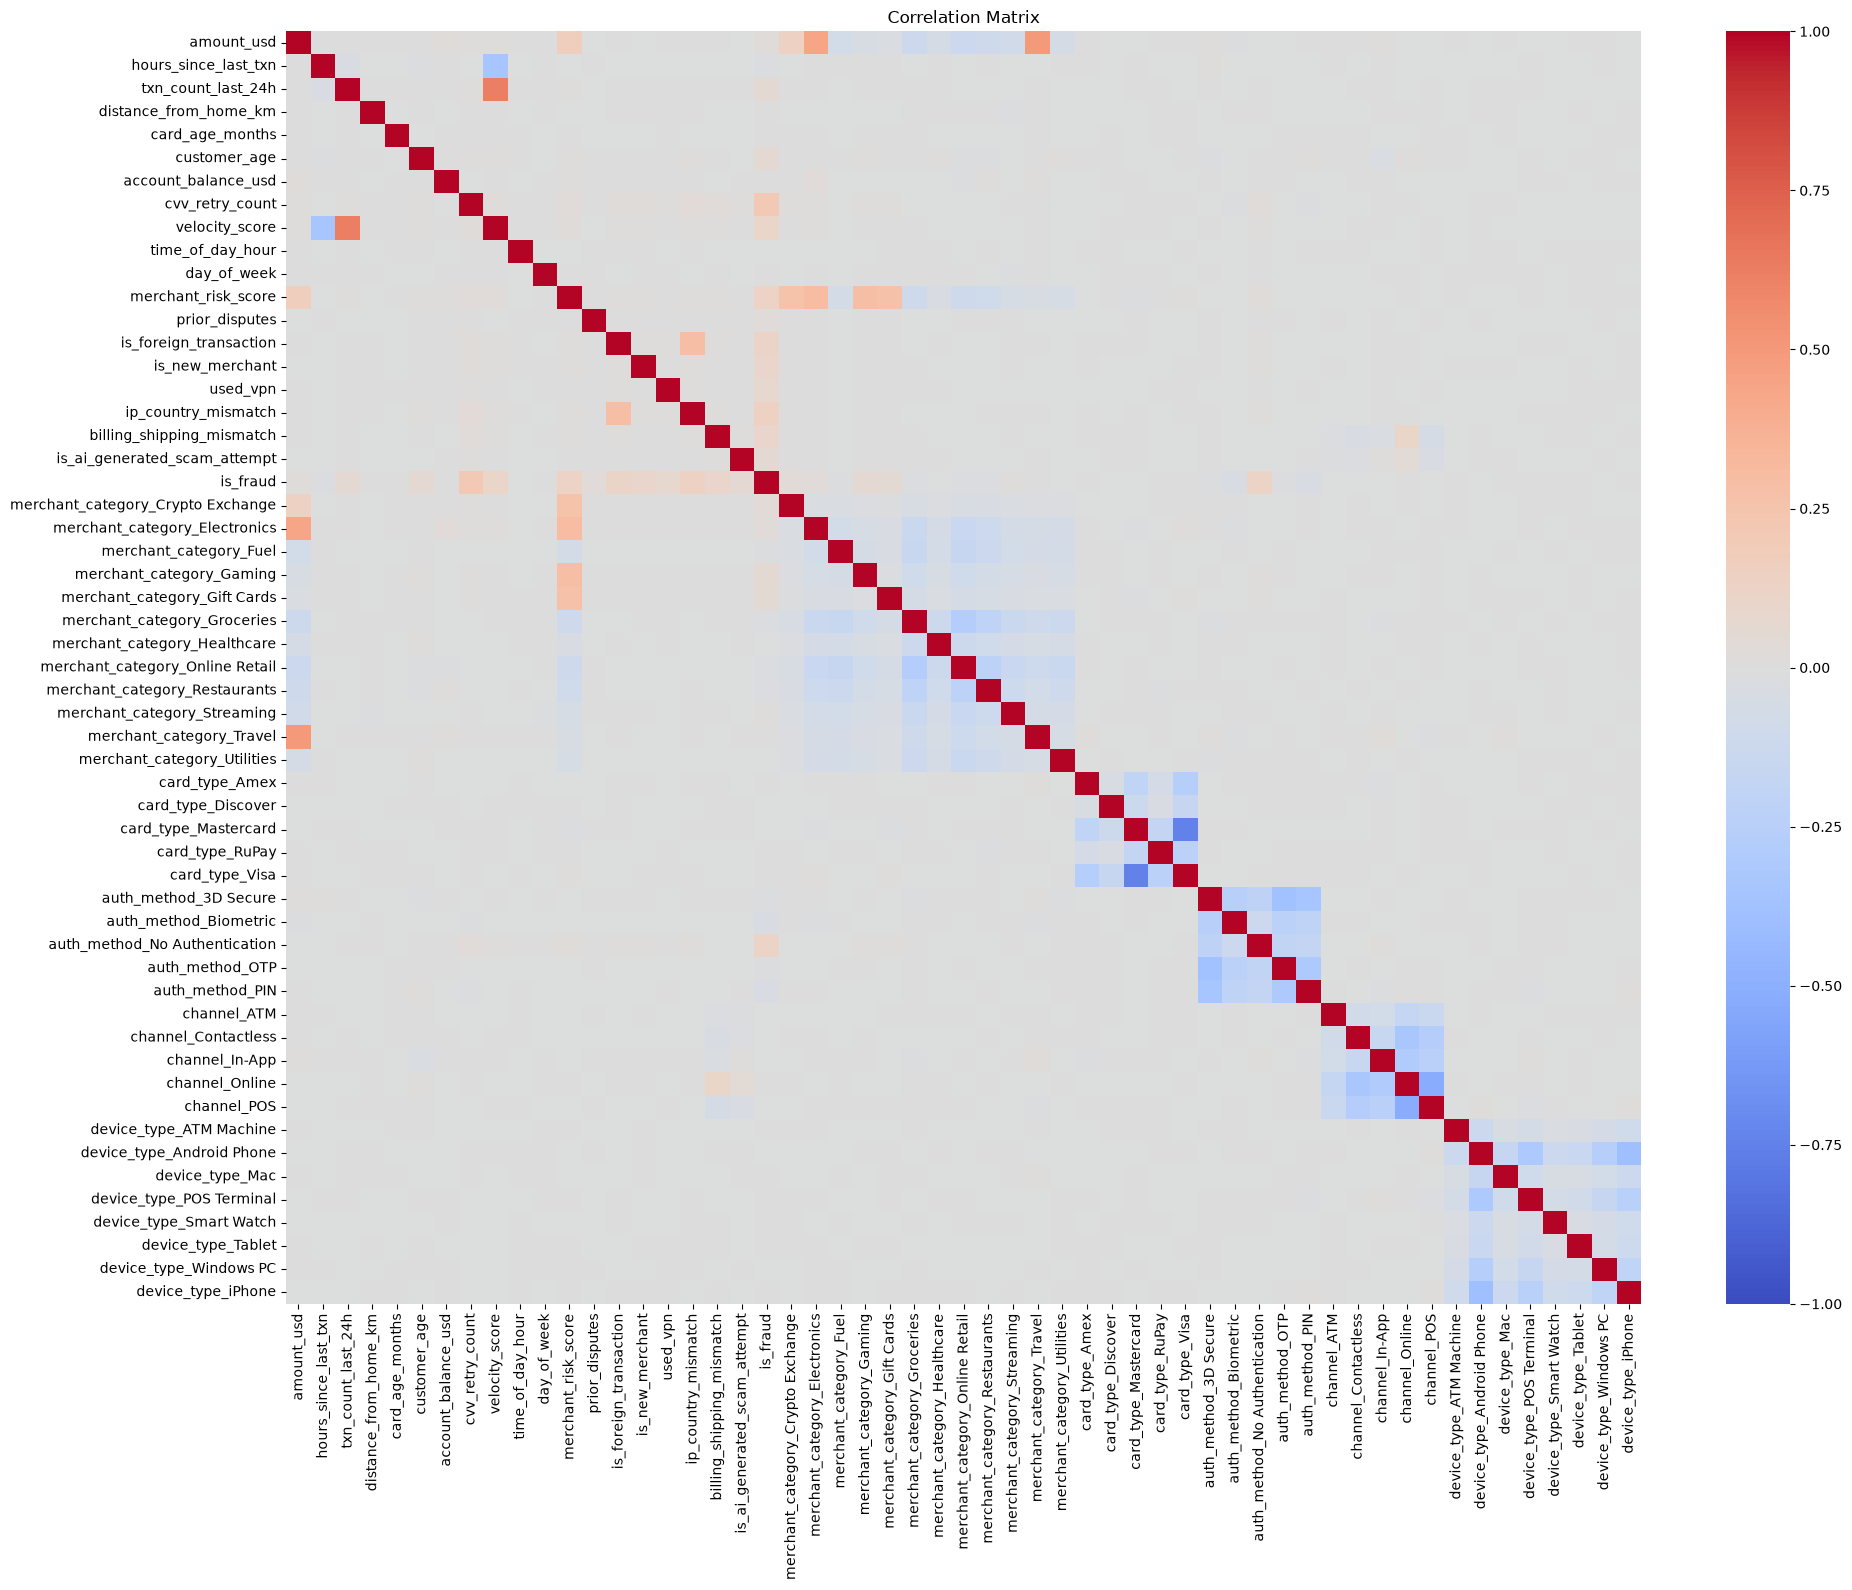

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = df.drop(columns=['id'], errors='ignore')

# Tính tương quan
corr_matrix = df.corr(numeric_only=True)

# Vẽ Heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd

corr = df.drop(
    columns=['id', 'is_fraud'],
    errors='ignore'
).corr(numeric_only=True)

# Lấy nửa trên của ma trận
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Chuyển thành bảng các cặp
high_corr = upper.stack().reset_index()

high_corr.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

# Lọc các cặp có tương quan mạnh
high_corr = high_corr[
    high_corr['Correlation'].abs() >= 0.7
]

# Sắp xếp theo độ mạnh
high_corr = high_corr.sort_values(
    'Correlation',
    key=abs,
    ascending=False
)

display(high_corr)

,Feature 1,Feature 2,Correlation
1817,card_type_Mastercard,card_type_Visa,-0.746


In [13]:
# Tương quan của các đặc trưng với nhãn is_fraud
target_corr = corr_matrix['is_fraud'].drop('is_fraud')

# Sắp xếp theo độ mạnh tương quan
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

display(target_corr.to_frame('Correlation').round(4))

,Correlation
cvv_retry_count,0.2123
ip_country_mismatch,0.1483
merchant_risk_score,0.1254
auth_method_No Authentication,0.1213
is_foreign_transaction,0.1128
velocity_score,0.1016
is_new_merchant,0.1014
billing_shipping_mismatch,0.1011
used_vpn,0.0712
is_ai_generated_scam_attempt,0.0607


In [16]:

import pandas as pd
import numpy as np

# Chỉ chọn các cột số có ý nghĩa để kiểm tra Outlier
numeric_cols = [
    'amount_usd',
    'hours_since_last_txn',
    'txn_count_last_24h',
    'distance_from_home_km',
    'card_age_months',
    'customer_age',
    'account_balance_usd',
    'cvv_retry_count',
    'velocity_score',
    'merchant_risk_score',
    'prior_disputes'
]

outlier_report = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_report.append({
        'Feature': col,
        'Outlier Count': outliers.sum(),
        'Outlier (%)': outliers.mean() * 100,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound
    })

outlier_df = pd.DataFrame(outlier_report)

display(
    outlier_df.sort_values(
        'Outlier (%)',
        ascending=False
    ).round(2)
)


,Feature,Outlier Count,Outlier (%),Lower Bound,Upper Bound
10,prior_disputes,101564,14.51,0.00,0.00
0,amount_usd,70741,10.11,-25.14,84.06
7,cvv_retry_count,57872,8.27,0.00,0.00
1,hours_since_last_txn,32816,4.69,-8.51,19.81
6,account_balance_usd,29068,4.15,-1690.23,5041.37
3,distance_from_home_km,16770,2.40,-18.55,42.73
9,merchant_risk_score,13028,1.86,1.95,67.15
8,velocity_score,4276,0.61,-10.50,47.90
2,txn_count_last_24h,2704,0.39,-1.00,7.00
4,card_age_months,2253,0.32,31.00,63.00


In [21]:
df.to_csv("data_after_solve.csv", index = False)
print("saved success")

saved success
